In [8]:
import os
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
from tqdm import tqdm

# ==========================================
# ۱. مسیرهای ورودی و خروجی
# ==========================================
INPUT_DIR = './hard_streaming'
OUTPUT_DIR = './train_features_combined'
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ==========================================
# ۲. لود شبکه استخراج‌گر ResNet
# ==========================================
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet = nn.Sequential(*list(resnet.children())[:-1]).to(device)
resnet.eval()

print(f"در حال استخراج و مرتب‌سازی داده‌ها در {INPUT_DIR}...")

# ==========================================
# ۳. فرآیند هوشمند تبدیل و انتقال
# ==========================================
for file_name in tqdm(os.listdir(INPUT_DIR)):
    if not file_name.endswith('.pt'):
        continue
        
    input_path = os.path.join(INPUT_DIR, file_name)
    output_path = os.path.join(OUTPUT_DIR, file_name)
    
    if os.path.exists(output_path):
        continue
        
    try:
        # لود دیتای داخل فایل
        data = torch.load(input_path, weights_only=True)
        
        # بررسی هوشمند: آیا این فایل قبلاً ویژگی‌سازی شده است؟ (مثلاً سایزش [N, 512] است)
        if data.ndimension() == 2 and data.size(1) == 512:
            # فایل آماده است، فقط کپی شود
            torch.save(data.cpu(), output_path)
            continue
            
        # اگر فایل تصویر خام بود (۴ بعدی):
        if data.dtype == torch.uint8 or data.max() > 1.0:
            data = data.float() / 255.0
            
        data = data.to(device)
        
        with torch.no_grad():
            features = []
            for i in range(0, len(data), 32):
                batch = data[i:i+32]
                out = resnet(batch).squeeze(-1).squeeze(-1)
                features.append(out)
            
            video_features = torch.cat(features, dim=0)
            
        torch.save(video_features.cpu(), output_path)
        
    except Exception as e:
        print(f"\nخطا در پردازش {file_name}: {e}")

print("\nپردازش تمام شد! تمام ۱۴۰۰ فایل با موفقیت به بردار ۵۱۲ تایی تبدیل و در پوشه train_features_combined جمع‌آوری شدند.")

در حال استخراج و مرتب‌سازی داده‌ها در ./hard_streaming...


100%|██████████| 1400/1400 [20:35<00:00,  1.13it/s] 


پردازش تمام شد! تمام ۱۴۰۰ فایل با موفقیت به بردار ۵۱۲ تایی تبدیل و در پوشه train_features_combined جمع‌آوری شدند.


[I 2026-10-31 15:01:43,793] A new study created in memory with name: no-name-e3264625-c3fd-4ce3-9a77-c7254250da26


در حال بارگذاری داده‌های آموزش...

--- شروع فاز ۱: جستجوی خودکار بهترین تنظیمات با Optuna ---


[I 2026-10-31 15:02:27,737] Trial 0 finished with value: 0.6885245901639344 and parameters: {'hidden_size': 256, 'lr': 0.0006485707573198049, 'alpha': 0.8435379193063235, 'dropout': 0.3840191972936521, 'threshold': 0.5433405867644455}. Best is trial 0 with value: 0.6885245901639344.
[I 2026-10-31 15:03:09,817] Trial 1 finished with value: 0.6086956521739131 and parameters: {'hidden_size': 256, 'lr': 0.00028304762593551585, 'alpha': 0.6963308504399892, 'dropout': 0.5863848546533719, 'threshold': 0.6525486679009814}. Best is trial 0 with value: 0.6885245901639344.
[I 2026-10-31 15:03:50,324] Trial 2 finished with value: 0.6956521739130435 and parameters: {'hidden_size': 256, 'lr': 0.0012072494236191117, 'alpha': 0.7003726425656374, 'dropout': 0.4503341401892873, 'threshold': 0.5578750463908122}. Best is trial 2 with value: 0.6956521739130435.
[I 2026-10-31 15:04:15,889] Trial 3 finished with value: 0.6936708860759494 and parameters: {'hidden_size': 128, 'lr': 0.0005250451913849773, 'alph


=== بهترین پارامترهای کشف شده ===
hidden_size: 256
lr: 0.0018581061267481094
alpha: 0.8337607611054322
dropout: 0.4415158475354136
threshold: 0.6296157137299008

--- شروع فاز ۲: آموزش مدل نهایی با بهترین تنظیمات ---
Epoch 01/30 | Train Loss: 0.0631 | Val Loss: 0.0576 | Val Acc: 0.6286
Epoch 02/30 | Train Loss: 0.0570 | Val Loss: 0.0542 | Val Acc: 0.6286
Epoch 03/30 | Train Loss: 0.0546 | Val Loss: 0.0524 | Val Acc: 0.6714
Epoch 04/30 | Train Loss: 0.0525 | Val Loss: 0.0503 | Val Acc: 0.7179
Epoch 05/30 | Train Loss: 0.0496 | Val Loss: 0.0495 | Val Acc: 0.7464
Epoch 06/30 | Train Loss: 0.0520 | Val Loss: 0.0527 | Val Acc: 0.6000
Epoch 07/30 | Train Loss: 0.0506 | Val Loss: 0.0487 | Val Acc: 0.7071
Epoch 08/30 | Train Loss: 0.0481 | Val Loss: 0.0494 | Val Acc: 0.6893
Epoch 09/30 | Train Loss: 0.0479 | Val Loss: 0.0477 | Val Acc: 0.7500
Epoch 10/30 | Train Loss: 0.0453 | Val Loss: 0.0474 | Val Acc: 0.7679
Epoch 11/30 | Train Loss: 0.0452 | Val Loss: 0.0468 | Val Acc: 0.7679
Epoch 12/30 |

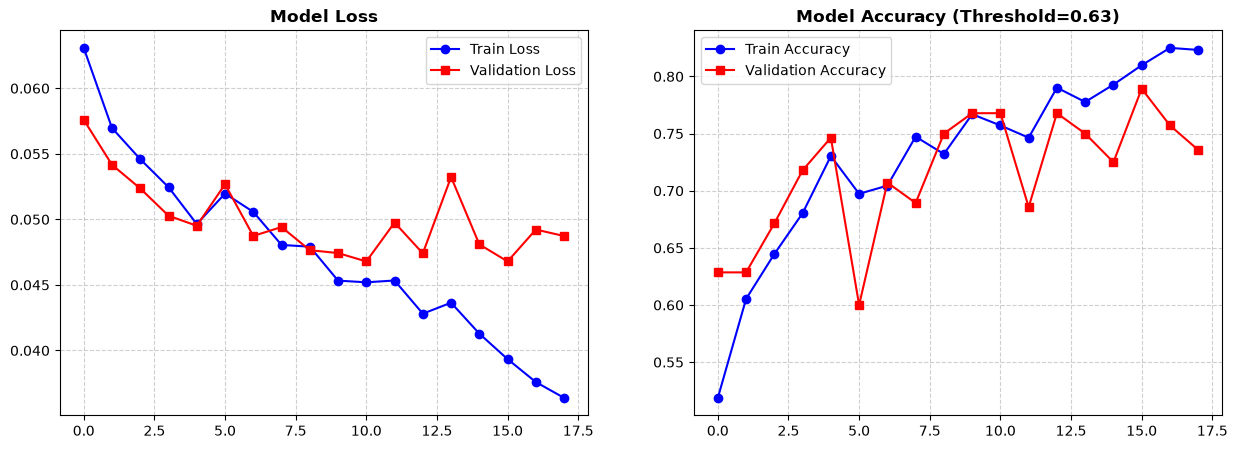


=== نتایج نهایی روی دیتای تست (آستانه 0.63) ===
Accuracy:  0.5000
Precision: 0.5000
Recall:    0.0100
F1-Score:  0.0196


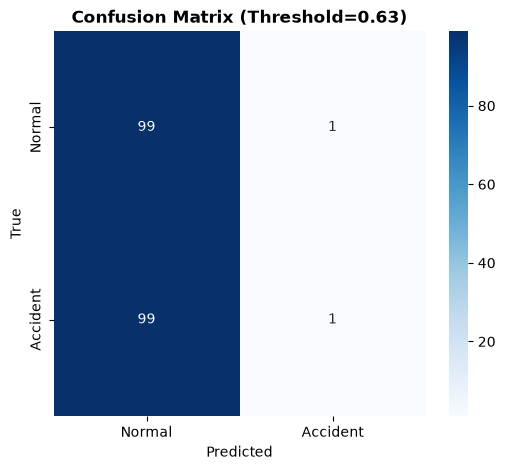

In [11]:
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import optuna

# ==========================================
# ۱. تنظیمات مسیر داده‌ها
# ==========================================
TRAIN_FEATURES_DIR = './train_features_combined'  # ۱۴۰۰ فایل
TEST_FEATURES_DIR = './test_features'             # ۲۰۰ فایل تست
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ==========================================
# ۲. بارگذاری داده‌های برداری
# ==========================================
class FeatureVideoDataset(Dataset):
    def __init__(self, data_dir, max_frames=100):
        self.data_dir = data_dir
        self.file_names = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        self.max_frames = max_frames

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.data_dir, self.file_names[idx])
        match = re.search(r'label_(\d+)', self.file_names[idx])
        label = int(match.group(1)) if match else 0
        features = torch.load(file_path, weights_only=True)
        
        seq_len = features.size(0)
        if seq_len < self.max_frames:
            padding = torch.zeros(self.max_frames - seq_len, 512)
            features = torch.cat((features, padding), dim=0)
        else:
            features = features[:self.max_frames, :]
            
        return features, torch.tensor(label, dtype=torch.float32)

print(f"در حال بارگذاری داده‌های آموزش...")
full_train_dataset = FeatureVideoDataset(TRAIN_FEATURES_DIR, max_frames=100)
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(FeatureVideoDataset(TEST_FEATURES_DIR, max_frames=100), batch_size=32, shuffle=False)

# ==========================================
# ۳. معماری BiLSTM و تابع خطا
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.60, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        p = inputs.clamp(1e-6, 1 - 1e-6)
        term1 = -targets * self.alpha * (1 - p)**self.gamma * torch.log(p)
        term2 = -(1 - targets) * (1 - self.alpha) * p**self.gamma * torch.log(1 - p)
        return torch.mean(term1 + term2)

class AccidentBiLSTM(nn.Module):
    def __init__(self, input_size=512, hidden_size=256, num_layers=1, dropout=0.49):
        super(AccidentBiLSTM, self).__init__()
        self.input_noise = nn.Dropout(p=0.2)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                            batch_first=True, dropout=0, bidirectional=True)
        self.fc1 = nn.Linear(hidden_size * 2, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.input_noise(x)
        lstm_out, _ = self.lstm(x)
        pooled_out, _ = torch.max(lstm_out, dim=1) 
        x = self.dropout(self.relu(self.fc1(pooled_out)))
        return self.sigmoid(self.fc2(x)).squeeze(-1)

# ==========================================
# ۴. فاز اکتشاف (جستجوی خودکار Optuna)
# ==========================================
def objective(trial):
    # پارامترهایی که Optuna به صورت هوشمند تغییر می‌دهد
    hidden_size = trial.suggest_categorical('hidden_size', [128, 256])
    lr = trial.suggest_float('lr', 1e-4, 3e-3, log=True)
    alpha = trial.suggest_float('alpha', 0.50, 0.85)
    dropout = trial.suggest_float('dropout', 0.3, 0.6)
    threshold = trial.suggest_float('threshold', 0.45, 0.70)

    model = AccidentBiLSTM(hidden_size=hidden_size, dropout=dropout).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=0.0001)
    criterion = FocalLoss(alpha=alpha, gamma=2.0)

    # آموزش سریع (۸ ایپاک) برای سنجش کیفیت پارامترها
    for epoch in range(8):
        model.train()
        for features, labels in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(features.to(device)), labels.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

    # ارزیابی این ترکیب روی دیتای ولیدیشن
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for features, labels in val_loader:
            preds = (model(features.to(device)) >= threshold).float().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    return f1_score(all_labels, all_preds, zero_division=0)

print("\n--- شروع فاز ۱: جستجوی خودکار بهترین تنظیمات با Optuna ---")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=15) # تست ۱۵ ترکیب مختلف

best_params = study.best_params
print("\n=== بهترین پارامترهای کشف شده ===")
for k, v in best_params.items():
    print(f"{k}: {v}")
print("=================================\n")

# ==========================================
# ۵. فاز آموزش نهایی (استفاده از نتایج Optuna)
# ==========================================
print("--- شروع فاز ۲: آموزش مدل نهایی با بهترین تنظیمات ---")

# ساخت مدل با بهترین مقادیر
final_model = AccidentBiLSTM(
    hidden_size=best_params['hidden_size'], 
    dropout=best_params['dropout']
).to(device)

optimizer = optim.Adam(final_model.parameters(), lr=best_params['lr'], weight_decay=0.0001)
criterion = FocalLoss(alpha=best_params['alpha'], gamma=2.0)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
BEST_THRESHOLD = best_params['threshold']

epochs, patience, patience_limit = 30, 0, 7
best_val_loss = float('inf')
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(epochs):
    final_model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    
    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = final_model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        preds = (outputs >= BEST_THRESHOLD).float()
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)
        
    final_model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = final_model(features)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            preds = (outputs >= BEST_THRESHOLD).float()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss_epoch = val_loss / len(val_loader)
    scheduler.step(val_loss_epoch)
    
    train_losses.append(train_loss / len(train_loader))
    val_losses.append(val_loss_epoch)
    train_accs.append(train_correct / train_total)
    val_accs.append(val_correct / val_total)
    
    print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Val Acc: {val_accs[-1]:.4f}")
    
    if val_loss_epoch < best_val_loss:
        best_val_loss = val_loss_epoch
        torch.save(final_model.state_dict(), 'best_final_model_optuna.pth')
        patience = 0
    else:
        patience += 1
        if patience >= patience_limit:
            print(f"توقف زودهنگام در ایپاک {epoch+1}!")
            break

# ==========================================
# ۶. رسم نمودارها و ارزیابی نهایی
# ==========================================
final_model.load_state_dict(torch.load('best_final_model_optuna.pth', weights_only=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(train_losses, label='Train Loss', color='blue', marker='o')
axes[0].plot(val_losses, label='Validation Loss', color='red', marker='s')
axes[0].set_title('Model Loss', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(train_accs, label='Train Accuracy', color='blue', marker='o')
axes[1].plot(val_accs, label='Validation Accuracy', color='red', marker='s')
axes[1].set_title(f'Model Accuracy (Threshold={BEST_THRESHOLD:.2f})', fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.show()

final_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)
        outputs = final_model(features)
        preds = (outputs >= BEST_THRESHOLD).float().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(f"\n=== نتایج نهایی روی دیتای تست (آستانه {BEST_THRESHOLD:.2f}) ===")
print(f"Accuracy:  {accuracy_score(all_labels, all_preds):.4f}")
print(f"Precision: {precision_score(all_labels, all_preds, zero_division=0):.4f}")
print(f"Recall:    {recall_score(all_labels, all_preds, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(all_labels, all_preds, zero_division=0):.4f}")

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Accident'], yticklabels=['Normal', 'Accident'])
plt.title(f'Confusion Matrix (Threshold={BEST_THRESHOLD:.2f})', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

✅ تعداد کل داده‌های آموزش بارگذاری شده: 1400 فایل

--- شروع آموزش قدرتمند با دیتای غنی‌شده ---
Epoch 01/40 | Train Loss: 0.0648 | Val Loss: 0.0617 | Val Acc: 0.4750
Epoch 02/40 | Train Loss: 0.0610 | Val Loss: 0.0605 | Val Acc: 0.4750
Epoch 03/40 | Train Loss: 0.0591 | Val Loss: 0.0599 | Val Acc: 0.4750
Epoch 04/40 | Train Loss: 0.0578 | Val Loss: 0.0604 | Val Acc: 0.4750
Epoch 05/40 | Train Loss: 0.0566 | Val Loss: 0.0574 | Val Acc: 0.4750
Epoch 06/40 | Train Loss: 0.0542 | Val Loss: 0.0566 | Val Acc: 0.5464
Epoch 07/40 | Train Loss: 0.0529 | Val Loss: 0.0547 | Val Acc: 0.5679
Epoch 08/40 | Train Loss: 0.0512 | Val Loss: 0.0544 | Val Acc: 0.5393
Epoch 09/40 | Train Loss: 0.0507 | Val Loss: 0.0538 | Val Acc: 0.5500
Epoch 10/40 | Train Loss: 0.0485 | Val Loss: 0.0527 | Val Acc: 0.5857
Epoch 11/40 | Train Loss: 0.0493 | Val Loss: 0.0595 | Val Acc: 0.4857
Epoch 12/40 | Train Loss: 0.0470 | Val Loss: 0.0511 | Val Acc: 0.6286
Epoch 13/40 | Train Loss: 0.0444 | Val Loss: 0.0519 | Val Acc: 0.

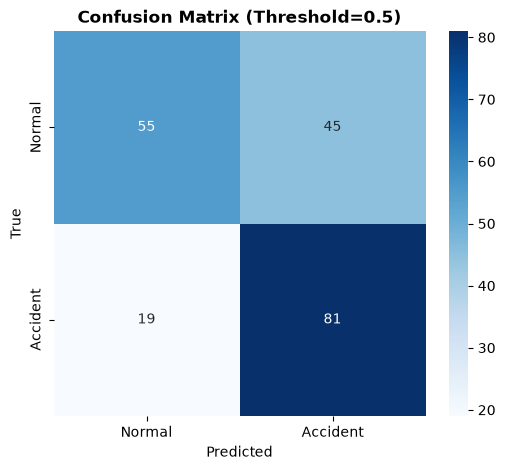

In [12]:
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# ==========================================
# ۱. مسیرها و تنظیمات تهاجمی (Aggressive Tuning)
# ==========================================
TRAIN_FEATURES_DIR = './train_features_combined'  
TEST_FEATURES_DIR = './test_features'             
DECISION_THRESHOLD = 0.50  # بازگشت به آستانه نرمال برای عبور از فروپاشی
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class FeatureVideoDataset(Dataset):
    def __init__(self, data_dir, max_frames=100):
        self.data_dir = data_dir
        self.file_names = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        self.max_frames = max_frames

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.data_dir, self.file_names[idx])
        match = re.search(r'label_(\d+)', self.file_names[idx])
        label = int(match.group(1)) if match else 0
        features = torch.load(file_path, weights_only=True)
        
        seq_len = features.size(0)
        if seq_len < self.max_frames:
            padding = torch.zeros(self.max_frames - seq_len, 512)
            features = torch.cat((features, padding), dim=0)
        else:
            features = features[:self.max_frames, :]
            
        return features, torch.tensor(label, dtype=torch.float32)

full_train_dataset = FeatureVideoDataset(TRAIN_FEATURES_DIR, max_frames=100)
print(f"✅ تعداد کل داده‌های آموزش بارگذاری شده: {len(full_train_dataset)} فایل")

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(FeatureVideoDataset(TEST_FEATURES_DIR, max_frames=100), batch_size=32, shuffle=False)

# ==========================================
# ۲. معماری و تابع خطای وزن‌دار شده
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.80, gamma=2.0): # آلفای 0.80: جریمه سنگین برای از دست دادن تصادف
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        p = inputs.clamp(1e-6, 1 - 1e-6)
        term1 = -targets * self.alpha * (1 - p)**self.gamma * torch.log(p)
        term2 = -(1 - targets) * (1 - self.alpha) * p**self.gamma * torch.log(1 - p)
        return torch.mean(term1 + term2)

class AccidentBiLSTM(nn.Module):
    def __init__(self, input_size=512, hidden_size=256, num_layers=1, dropout=0.3):
        super(AccidentBiLSTM, self).__init__()
        self.input_noise = nn.Dropout(p=0.1) # نویز ورودی کمتر برای جلوگیری از تخریب داده‌های سخت
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, bidirectional=True)
        self.fc1 = nn.Linear(hidden_size * 2, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.input_noise(x)
        lstm_out, _ = self.lstm(x)
        pooled_out, _ = torch.max(lstm_out, dim=1) 
        x = self.dropout(self.relu(self.fc1(pooled_out)))
        return self.sigmoid(self.fc2(x)).squeeze(-1)

# ==========================================
# ۳. آموزش نهایی مدل
# ==========================================
final_model = AccidentBiLSTM().to(device)
optimizer = optim.Adam(final_model.parameters(), lr=0.0005, weight_decay=0.0001)
criterion = FocalLoss(alpha=0.80, gamma=2.0)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

epochs, patience, patience_limit = 40, 0, 7
best_val_loss = float('inf')
train_losses, val_losses, train_accs, val_accs = [], [], [], []

print("\n--- شروع آموزش قدرتمند با دیتای غنی‌شده ---")
for epoch in range(epochs):
    final_model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    
    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = final_model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        preds = (outputs >= DECISION_THRESHOLD).float()
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)
        
    final_model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = final_model(features)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            preds = (outputs >= DECISION_THRESHOLD).float()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss_epoch = val_loss / len(val_loader)
    scheduler.step(val_loss_epoch)
    
    train_losses.append(train_loss / len(train_loader))
    val_losses.append(val_loss_epoch)
    train_accs.append(train_correct / train_total)
    val_accs.append(val_correct / val_total)
    
    print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Val Acc: {val_accs[-1]:.4f}")
    
    if val_loss_epoch < best_val_loss:
        best_val_loss = val_loss_epoch
        torch.save(final_model.state_dict(), 'best_final_model_1400.pth')
        patience = 0
    else:
        patience += 1
        if patience >= patience_limit:
            print(f"توقف زودهنگام در ایپاک {epoch+1} اعمال شد!")
            break

# ==========================================
# ۴. ارزیابی نهایی روی دیتای تست
# ==========================================
final_model.load_state_dict(torch.load('best_final_model_1400.pth', weights_only=True))
final_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)
        outputs = final_model(features)
        preds = (outputs >= DECISION_THRESHOLD).float().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(f"\n=== نتایج نهایی روی دیتای تست (آستانه {DECISION_THRESHOLD}) ===")
print(f"Accuracy:  {accuracy_score(all_labels, all_preds):.4f}")
print(f"Precision: {precision_score(all_labels, all_preds, zero_division=0):.4f}")
print(f"Recall:    {recall_score(all_labels, all_preds, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(all_labels, all_preds, zero_division=0):.4f}")

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Accident'], yticklabels=['Normal', 'Accident'])
plt.title(f'Confusion Matrix (Threshold={DECISION_THRESHOLD})', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

inja model ro ba hamoon 1000sample ghabli be ezafeye 400 sample ba sharayete gheyre addi , train kardim va natije mosbat nabood va ba threshold ham be natijeye mosbat resid ama kamtar az model ke ba focal loss train shod